Shape: (156, 8)
Missing values: 0
Date gaps (days between rows): {7.0: 155}
Date range: 2023-01-02 to 2025-12-22

               count                 mean                  min  \
date             156  2024-06-27 12:00:00  2023-01-02 00:00:00   
google_search  156.0              14774.0               7780.0   
meta           156.0               8399.0               3750.0   
microsoft      156.0               1784.0                937.0   
youtube        156.0               3973.0                  0.0   
promo          156.0                  0.0                  0.0   
price_index    156.0                  1.0                  1.0   
revenue        156.0             184935.0             121294.0   

                               25%                  50%                  75%  \
date           2023-09-30 06:00:00  2024-06-27 12:00:00  2025-03-25 18:00:00   
google_search              12128.0              14488.0              16947.0   
meta                        6279.0               79

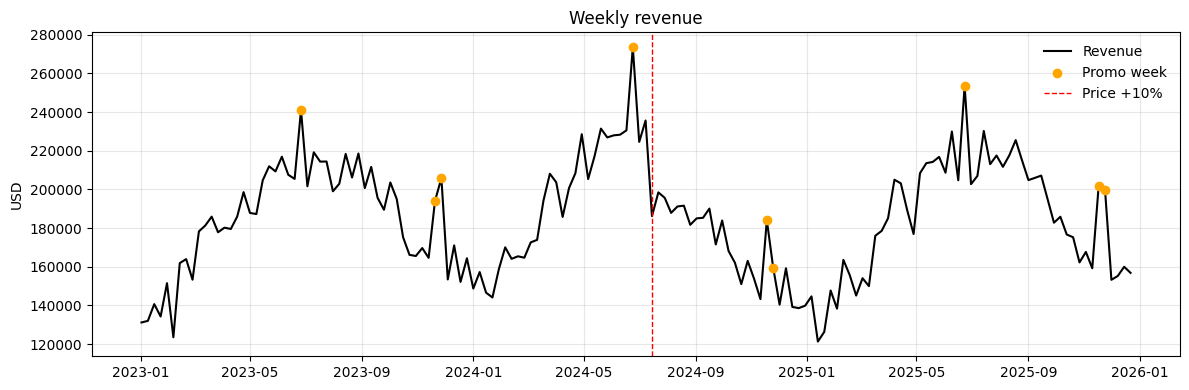

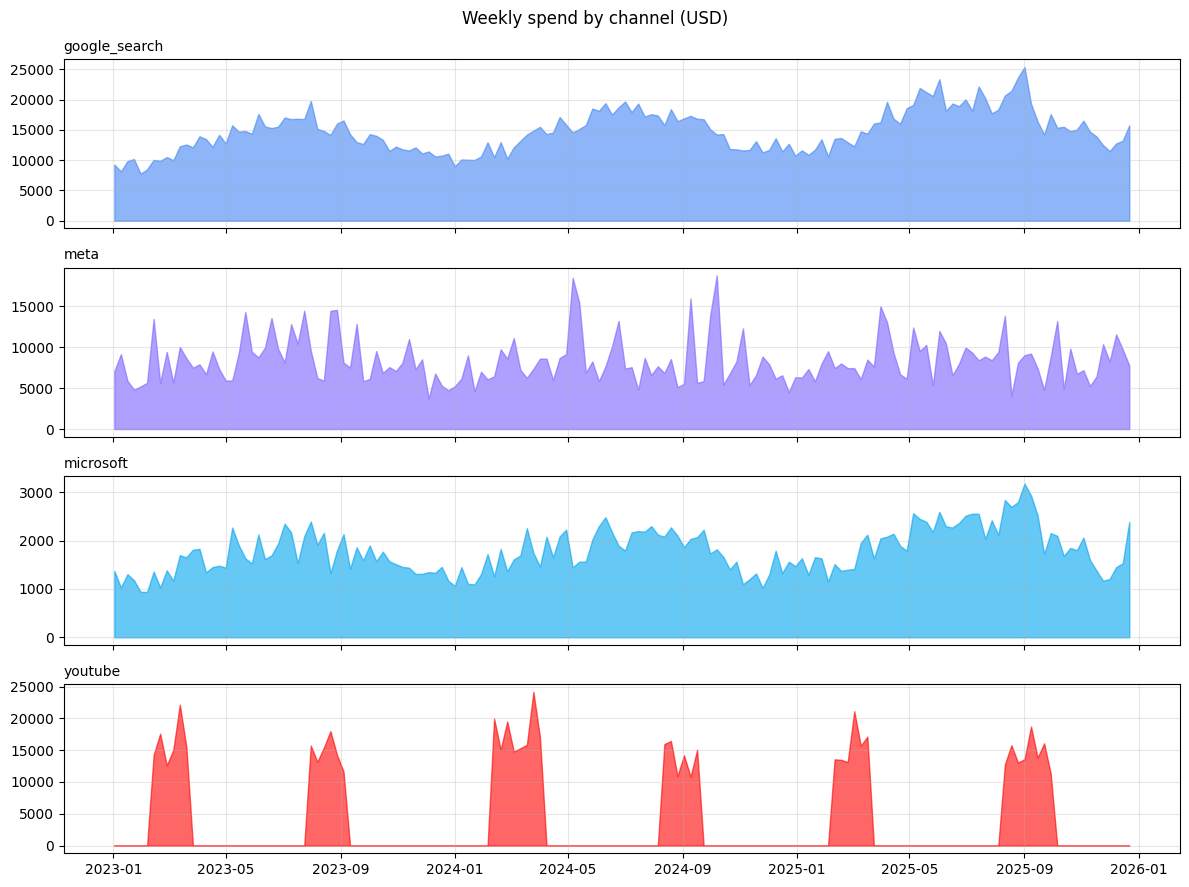

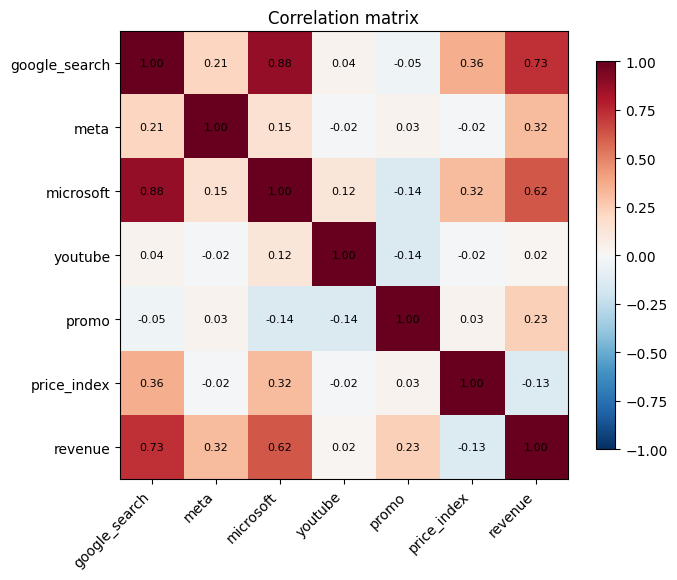


Variance Inflation Factor
 google_search    4.7
meta             1.1
microsoft        4.7
youtube          1.0
dtype: float64


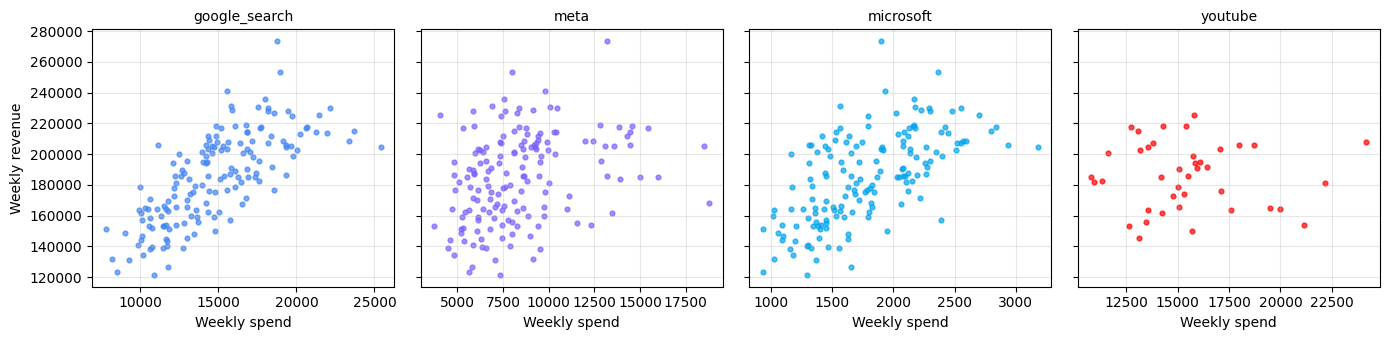


Naive regression: revenue per $1 of spend
 google_search    6.64
meta             1.69
microsoft       -6.06
youtube          0.02
Name: naive_roas, dtype: float64


In [1]:
# ============================================================
# Project 3 - Marketing Mix Model
# Step 2: Exploratory Data Analysis
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/paolofelix/marketing-mix-model/main/data/mmm_data.csv"
df = pd.read_csv(URL, parse_dates=["date"])

channels = ["google_search", "meta", "microsoft", "youtube"]
colors = {"google_search": "#4285F4", "meta": "#7B61FF", "microsoft": "#00A4EF", "youtube": "#FF0000"}
os.makedirs("figures", exist_ok=True)

# ------------------------------------------------------------
# 1. Data quality checks
# ------------------------------------------------------------
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Date gaps (days between rows):", df["date"].diff().dt.days.value_counts().to_dict())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print()
print(df.describe().round(0).T)

# ------------------------------------------------------------
# 2. Spend mix
# ------------------------------------------------------------
totals = df[channels].sum()
mix = pd.DataFrame({
    "total_spend": totals.round(0),
    "share_of_spend": (totals / totals.sum()).round(3),
    "weeks_active": (df[channels] > 0).sum(),
    "avg_weekly_spend_when_active": (totals / (df[channels] > 0).sum()).round(0),
})
print("\nSpend mix\n", mix)

# ------------------------------------------------------------
# 3. Revenue over time, with promos and the price change
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["revenue"], color="black", lw=1.5, label="Revenue")
promo_weeks = df.loc[df["promo"] == 1, "date"]
ax.scatter(promo_weeks, df.loc[df["promo"] == 1, "revenue"], color="orange", zorder=3, label="Promo week")
price_change = df.loc[df["price_index"].diff() > 0, "date"].iloc[0]
ax.axvline(price_change, color="red", ls="--", lw=1, label="Price +10%")
ax.set_title("Weekly revenue")
ax.set_ylabel("USD")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/01_revenue_over_time.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 4. Spend by channel over time (small multiples)
# ------------------------------------------------------------
fig, axes = plt.subplots(len(channels), 1, figsize=(12, 9), sharex=True)
for ax, ch in zip(axes, channels):
    ax.fill_between(df["date"], df[ch], color=colors[ch], alpha=0.6)
    ax.set_title(ch, loc="left", fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle("Weekly spend by channel (USD)")
plt.tight_layout()
plt.savefig("figures/02_spend_by_channel.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 5. Correlation matrix
# ------------------------------------------------------------
corr = df[channels + ["promo", "price_index", "revenue"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("figures/03_correlation_matrix.png", dpi=150)
plt.show()

# Multicollinearity check: Variance Inflation Factor (>5 = problem)
vif = pd.Series(np.diag(np.linalg.inv(df[channels].corr().values)), index=channels)
print("\nVariance Inflation Factor\n", vif.round(1))

# ------------------------------------------------------------
# 6. Spend vs revenue scatter per channel
# ------------------------------------------------------------
fig, axes = plt.subplots(1, len(channels), figsize=(14, 3.5), sharey=True)
for ax, ch in zip(axes, channels):
    active = df[ch] > 0
    ax.scatter(df.loc[active, ch], df.loc[active, "revenue"], s=12, color=colors[ch], alpha=0.7)
    ax.set_title(ch, fontsize=10)
    ax.set_xlabel("Weekly spend")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Weekly revenue")
plt.tight_layout()
plt.savefig("figures/04_spend_vs_revenue.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# 7. Why we need an MMM: a naive linear regression
#    revenue ~ spend per channel (no adstock, no saturation, no controls)
# ------------------------------------------------------------
X = np.column_stack([np.ones(len(df)), df[channels]])
coefs = np.linalg.lstsq(X, df["revenue"], rcond=None)[0]
naive = pd.Series(coefs[1:], index=channels, name="naive_roas")
print("\nNaive regression: revenue per $1 of spend\n", naive.round(2))